## Recurrent PPO with LSTM: Droplet Protocol Tracing and Reverse Engineering

This notebook implements Recurrent Proximal Policy Optimization (RecurrentPPO) with LSTM architecture for reverse-engineering droplet protocols on DMFBs. 

### Key Features:
- **LSTM**: Traditional recurrent memory for short-term dependencies
- **On-Policy Learning**: PPO-style policy gradient updates
- **Action Masking**: Belief-based masking via logit manipulation
 
### Architecture Options:
1. **LSTM (Default)**: Fast, baseline with 256 hidden units

### References

```bibtex
@misc{schulman2017proximalpolicyoptimizationalgorithms,
      title={Proximal Policy Optimization Algorithms}, 
      author={John Schulman and Filip Wolski and Prafulla Dhariwal and Alec Radford and Oleg Klimov},
      year={2017},
      eprint={1707.06347},
      archivePrefix={arXiv},
      primaryClass={cs.LG},
      url={https://arxiv.org/abs/1707.06347}, 
}

## Import necessary libraries

In [1]:
# importing necessary libraries
import time
import os 
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
from torch.utils.tensorboard import SummaryWriter
from torch.distributions import Categorical
from tqdm import tqdm
import pickle
import json 
import matplotlib.pyplot as plt
import gymnasium as gym

## RecurrentPPO Agent with LSTM Support

**RecurrentPPOAgent** is a wrapper around SB3-Contrib's RecurrentPPO with action masking support.

### Architecture
- **Feature Extractor** → **LSTM** → **Actor (Policy) + Critic (Value) Heads**
- LSTM: 256 hidden units (default)

### Key Components
1. **On-Policy Buffer**: Rollout storage for PPO updates
2. **Network**: LSTM-based actor-critic network
3. **Training**: PPO with clipped objective and GAE
4. **Action Masking**: Invalid actions masked via logit manipulation

In [ ]:
# Import custom environment and feature extractor
from Env import VoltageDistributionEnv
from CustomFeatureExtractor import CustomFeatureExtractor


def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    """Initialize layer with orthogonal weights."""
    torch.nn.init.orthogonal_(layer.weight, std)
    if layer.bias is not None:
        torch.nn.init.constant_(layer.bias, bias_const)
    return layer


class RecurrentPPOAgent:
    """
    Recurrent PPO Agent with LSTM Memory and Action Masking
    
    Architecture:
    - CustomFeatureExtractor for dict observation space (CNN + MLP)
    - LSTM for temporal memory (256 hidden units default)
    - Separate Actor/Critic heads with action masking via logit manipulation
    - Vectorized environment support for parallel training
    
    This is a custom implementation (not SB3) to enable proper action masking.
    Based on RecurrentPPO_TrXL.ipynb but with LSTM instead of Transformer.
    """
    
    def __init__(self,
                 env_constructor,
                 feature_extractor_constructor,
                 action_dim,

                 # LSTM hyperparameters
                 lstm_hidden_size=256,
                 lstm_num_layers=1,

                 # PPO hyperparameters
                 gamma=0.99,
                 gae_lambda=0.95,
                 lr=1e-4,
                 clip_coef=0.2,
                 vf_coef=0.5,
                 ent_coef=0.01,
                 max_grad_norm=0.5,
                 update_epochs=4,
                 num_minibatches=4,
                 norm_adv=True,
                 clip_vloss=True,

                 # Training settings
                 num_envs=4,
                 num_steps=128,
                 training_steps=10_000,

                 # Logging
                 tensorboard_dir=None,
                 run_name=None,

                 # Action masking
                 action_mask=False):
        
        self.env_constructor = env_constructor
        self.feature_extractor_constructor = feature_extractor_constructor
        self.action_dim = action_dim
        
        # LSTM params
        self.lstm_hidden_size = lstm_hidden_size
        self.lstm_num_layers = lstm_num_layers
        
        # PPO params
        self.gamma = gamma
        self.gae_lambda = gae_lambda
        self.lr = lr
        self.clip_coef = clip_coef
        self.vf_coef = vf_coef
        self.ent_coef = ent_coef
        self.max_grad_norm = max_grad_norm
        self.update_epochs = update_epochs
        self.num_minibatches = num_minibatches
        self.norm_adv = norm_adv
        self.clip_vloss = clip_vloss
        
        # Training params
        self.num_envs = num_envs
        self.num_steps = num_steps
        self.training_steps = training_steps
        self.action_mask_enabled = action_mask
        
        # Device
        self.device = torch.device('cpu')
        
        # Single env instance to get observation space
        single_env = env_constructor()
        self.observation_space = single_env.observation_space
        single_env.close()
        
        # Build networks
        self.agent = self._build_agent()
        self.optimizer = optim.Adam(self.agent.parameters(), lr=lr)
        
        # TensorBoard
        if tensorboard_dir and run_name:
            log_dir = os.path.join(tensorboard_dir, run_name)
            self.writer = SummaryWriter(log_dir=log_dir)
            print(f"TensorBoard logging to: {log_dir}")
        elif tensorboard_dir:
            self.writer = SummaryWriter(log_dir=tensorboard_dir)
        else:
            self.writer = None
        
        # Counters
        self.global_step = 0
        self.episode_count = 0
        self.update_count = 0
        
        # Computed values
        self.batch_size = num_envs * num_steps
        self.minibatch_size = self.batch_size // num_minibatches
        
        print(f"\nRecurrentPPO Agent (LSTM) initialized")
        print(f"  LSTM: {lstm_hidden_size} hidden, {lstm_num_layers} layers")
        print(f"  Action dim: {action_dim}")
        print(f"  Action masking: {action_mask}\n")
    
    def _build_agent(self):
        """Build the PPO agent network with LSTM."""
        
        class PPOLSTMAgent(nn.Module):
            """PPO Agent with CustomFeatureExtractor and LSTM."""
            
            def __init__(self, parent):
                super().__init__()
                self.parent = parent
                
                # Feature extractor (CustomFeatureExtractor)
                self.feature_extractor = parent.feature_extractor_constructor(parent.observation_space)
                feat_dim = self.feature_extractor._features_dim
                
                # LSTM layer
                self.lstm = nn.LSTM(
                    input_size=feat_dim,
                    hidden_size=parent.lstm_hidden_size,
                    num_layers=parent.lstm_num_layers,
                    batch_first=True
                )
                
                # Initialize LSTM weights with orthogonal initialization
                for name, param in self.lstm.named_parameters():
                    if 'weight_ih' in name:
                        nn.init.orthogonal_(param)
                    elif 'weight_hh' in name:
                        nn.init.orthogonal_(param)
                    elif 'bias' in name:
                        nn.init.zeros_(param)
                
                # Actor head (policy)
                self.actor = nn.Sequential(
                    layer_init(nn.Linear(parent.lstm_hidden_size, parent.lstm_hidden_size)),
                    nn.ReLU(),
                    layer_init(nn.Linear(parent.lstm_hidden_size, parent.action_dim), std=0.01)
                )
                
                # Critic head (value)
                self.critic = nn.Sequential(
                    layer_init(nn.Linear(parent.lstm_hidden_size, parent.lstm_hidden_size)),
                    nn.ReLU(),
                    layer_init(nn.Linear(parent.lstm_hidden_size, 1), std=1.0)
                )
            
            def get_initial_lstm_state(self, batch_size):
                """Get zero-initialized LSTM hidden state."""
                h0 = torch.zeros(self.parent.lstm_num_layers, batch_size, self.parent.lstm_hidden_size).to(self.parent.device)
                c0 = torch.zeros(self.parent.lstm_num_layers, batch_size, self.parent.lstm_hidden_size).to(self.parent.device)
                return (h0, c0)
            
            def get_value(self, obs_dict, lstm_state):
                """Get value estimate for observations."""
                features = self.feature_extractor(obs_dict)
                # Add sequence dimension for LSTM
                features = features.unsqueeze(1)  # (B, 1, feat_dim)
                lstm_out, new_lstm_state = self.lstm(features, lstm_state)
                lstm_out = lstm_out.squeeze(1)  # (B, hidden_size)
                return self.critic(lstm_out).flatten(), new_lstm_state
            
            def get_action_and_value(self, obs_dict, lstm_state, action=None, action_mask=None):
                """Get action, log_prob, entropy, value, and new lstm_state."""
                features = self.feature_extractor(obs_dict)
                # Add sequence dimension for LSTM
                features = features.unsqueeze(1)  # (B, 1, feat_dim)
                lstm_out, new_lstm_state = self.lstm(features, lstm_state)
                lstm_out = lstm_out.squeeze(1)  # (B, hidden_size)
                
                # Get logits from actor
                logits = self.actor(lstm_out)
                
                # Apply action mask (set invalid action logits to -inf)
                if action_mask is not None:
                    logits = logits.masked_fill(action_mask == 0, float('-1e8'))
                
                # Create distribution
                dist = Categorical(logits=logits)
                
                if action is None:
                    action = dist.sample()
                
                log_prob = dist.log_prob(action)
                entropy = dist.entropy()
                
                # Value
                value = self.critic(lstm_out).flatten()
                
                return action, log_prob, entropy, value, new_lstm_state
        
        return PPOLSTMAgent(self).to(self.device)
    
    def _make_vec_env(self):
        """Create vectorized environments."""
        def make_env(idx):
            def thunk():
                env = self.env_constructor()
                env = gym.wrappers.RecordEpisodeStatistics(env)
                return env
            return thunk
    
        return gym.vector.SyncVectorEnv([make_env(i) for i in range(self.num_envs)])
    
    def _obs_dict_to_tensor(self, obs_dict, device):
        """Convert numpy observation dict to tensor dict."""
        return {k: torch.from_numpy(v).float().to(device) for k, v in obs_dict.items()}
    
    def train(self):
        """Main training loop with PPO and LSTM."""
        
        # Create vectorized environment
        envs = self._make_vec_env()
        
        # Storage buffers
        obs_buffer = {k: torch.zeros((self.num_steps, self.num_envs, *v.shape)).to(self.device)
                      for k, v in self.observation_space.spaces.items()}
        actions = torch.zeros((self.num_steps, self.num_envs), dtype=torch.long).to(self.device)
        log_probs = torch.zeros((self.num_steps, self.num_envs)).to(self.device)
        rewards = torch.zeros((self.num_steps, self.num_envs)).to(self.device)
        dones = torch.zeros((self.num_steps, self.num_envs)).to(self.device)
        values = torch.zeros((self.num_steps, self.num_envs)).to(self.device)
        action_masks_buffer = torch.ones((self.num_steps, self.num_envs, self.action_dim)).to(self.device)
        
        # LSTM state buffers - store (h, c) for each step
        lstm_h_buffer = torch.zeros((self.num_steps, self.lstm_num_layers, self.num_envs, self.lstm_hidden_size)).to(self.device)
        lstm_c_buffer = torch.zeros((self.num_steps, self.lstm_num_layers, self.num_envs, self.lstm_hidden_size)).to(self.device)
        
        # Initialize environment and LSTM state
        next_obs_np, infos = envs.reset()
        next_obs = self._obs_dict_to_tensor(next_obs_np, self.device)
        next_done = torch.zeros(self.num_envs).to(self.device)
        next_lstm_state = self.agent.get_initial_lstm_state(self.num_envs)
        
        # Get initial action masks
        next_action_mask = None
        if self.action_mask_enabled:
            next_action_mask = torch.ones((self.num_envs, self.action_dim)).to(self.device)
            if 'action_mask' in infos:
                for i in range(self.num_envs):
                    if infos['action_mask'][i] is not None:
                        next_action_mask[i] = torch.from_numpy(np.array(infos['action_mask'][i])).float().to(self.device)
        
        # Episode tracking
        episode_return_window = deque(maxlen=100)
        episode_normalized_return_window = deque(maxlen=100)
        episode_length_window = deque(maxlen=100)
        
        # Training loop
        num_iterations = self.training_steps // self.batch_size + 1
        
        with tqdm(total=self.training_steps, desc="Training RecurrentPPO (LSTM)", unit="step") as pbar:
            print("\n ________________________ Training RecurrentPPO Agent (LSTM) ________________________\n")
            
            for iteration in range(1, num_iterations + 1):
                if self.global_step >= self.training_steps:
                    break
                
                # Store initial LSTM state for this rollout
                initial_lstm_state = (next_lstm_state[0].clone(), next_lstm_state[1].clone())
                
                # Collect rollout
                for step in range(self.num_steps):
                    if self.global_step >= self.training_steps:
                        break
                    
                    self.global_step += self.num_envs
                    
                    with torch.no_grad():
                        # Store observations
                        for k in next_obs.keys():
                            obs_buffer[k][step] = next_obs[k]
                        dones[step] = next_done
                        
                        # Store LSTM state before step
                        lstm_h_buffer[step] = next_lstm_state[0]
                        lstm_c_buffer[step] = next_lstm_state[1]
                        
                        # Store action mask
                        if self.action_mask_enabled and next_action_mask is not None:
                            action_masks_buffer[step] = next_action_mask
                        
                        # Get action and value
                        action, log_prob, _, value, new_lstm_state = self.agent.get_action_and_value(
                            next_obs, next_lstm_state,
                            action_mask=next_action_mask if self.action_mask_enabled else None
                        )
                        
                        next_lstm_state = new_lstm_state
                        
                        # Store action, log_prob, value
                        actions[step] = action
                        log_probs[step] = log_prob
                        values[step] = value
                    
                    # Step environment
                    next_obs_np, reward, terminated, truncated, infos = envs.step(action.cpu().numpy())
                    next_done_np = np.logical_or(terminated, truncated)
                    
                    rewards[step] = torch.tensor(reward).to(self.device)
                    next_obs = self._obs_dict_to_tensor(next_obs_np, self.device)
                    next_done = torch.tensor(next_done_np).float().to(self.device)
                    
                    # Update action masks from info
                    if self.action_mask_enabled:
                        next_action_mask = torch.ones((self.num_envs, self.action_dim)).to(self.device)
                        if 'action_mask' in infos:
                            for i in range(self.num_envs):
                                mask = infos['action_mask'][i] if isinstance(infos['action_mask'], (list, np.ndarray)) else infos['action_mask']
                                if mask is not None:
                                    next_action_mask[i] = torch.from_numpy(np.array(mask)).float().to(self.device)
                    
                    # Reset LSTM state for done environments
                    for idx, done in enumerate(next_done_np):
                        if done:
                            next_lstm_state[0][:, idx, :] = 0
                            next_lstm_state[1][:, idx, :] = 0
                    
                    # Log episode completions
                    if 'episode' in infos and isinstance(infos['episode'], dict):
                        ep_data = infos['episode']
                        for i in range(self.num_envs):
                            if next_done_np[i]:
                                ep_return = float(ep_data['r'][i])
                                ep_length = int(ep_data['l'][i])
                                self.episode_count += 1
                                episode_return_window.append(ep_return)
                                normalized_return = ep_return / ep_length if ep_length > 0 else 0
                                episode_normalized_return_window.append(normalized_return)
                                episode_length_window.append(ep_length)
                                
                                if self.writer:
                                    self.writer.add_scalar('rollout/ep_rew_mean', np.mean(episode_return_window), self.global_step)
                                    self.writer.add_scalar('rollout/ep_len_mean', ep_length, self.global_step)
                                    self.writer.add_scalar('rollout/normalized_return_mean', np.mean(episode_normalized_return_window), self.global_step)
                                    self.writer.add_scalar('train/episode_reward', ep_return, self.episode_count)
                                    self.writer.add_scalar('rollout/normalized_return', normalized_return, self.episode_count)
                                    self.writer.flush()
                    
                    pbar.update(self.num_envs)
                
                # Bootstrap value
                with torch.no_grad():
                    next_value, _ = self.agent.get_value(next_obs, next_lstm_state)
                    
                    # GAE: Generalized Advantage Estimation
                    advantages = torch.zeros_like(rewards).to(self.device)
                    lastgaelam = 0
                    for t in reversed(range(self.num_steps)):
                        if t == self.num_steps - 1:
                            nextnonterminal = 1.0 - next_done
                            nextvalues = next_value
                        else:
                            nextnonterminal = 1.0 - dones[t + 1]
                            nextvalues = values[t + 1]
                        delta = rewards[t] + self.gamma * nextvalues * nextnonterminal - values[t]
                        advantages[t] = lastgaelam = delta + self.gamma * self.gae_lambda * nextnonterminal * lastgaelam
                    returns = advantages + values
                
                # Flatten batches
                b_obs = {k: v.reshape(-1, *v.shape[2:]) for k, v in obs_buffer.items()}
                b_log_probs = log_probs.reshape(-1)
                b_actions = actions.reshape(-1)
                b_advantages = advantages.reshape(-1)
                b_returns = returns.reshape(-1)
                b_values = values.reshape(-1)
                b_action_masks = action_masks_buffer.reshape(-1, self.action_dim)
                # Flatten LSTM states: (num_steps, num_layers, num_envs, hidden) -> (batch, num_layers, hidden)
                b_lstm_h = lstm_h_buffer.permute(0, 2, 1, 3).reshape(-1, self.lstm_num_layers, self.lstm_hidden_size)
                b_lstm_c = lstm_c_buffer.permute(0, 2, 1, 3).reshape(-1, self.lstm_num_layers, self.lstm_hidden_size)
                
                # PPO update
                clipfracs = []
                for epoch in range(self.update_epochs):
                    b_inds = torch.randperm(self.batch_size)
                    for start in range(0, self.batch_size, self.minibatch_size):
                        end = start + self.minibatch_size
                        mb_inds = b_inds[start:end]
                        
                        mb_obs = {k: v[mb_inds] for k, v in b_obs.items()}
                        # Reconstruct LSTM state for minibatch: need (num_layers, batch, hidden)
                        mb_lstm_h = b_lstm_h[mb_inds].permute(1, 0, 2).contiguous()
                        mb_lstm_c = b_lstm_c[mb_inds].permute(1, 0, 2).contiguous()
                        mb_lstm_state = (mb_lstm_h, mb_lstm_c)
                        
                        _, newlogprob, entropy, newvalue, _ = self.agent.get_action_and_value(
                            mb_obs, mb_lstm_state,
                            action=b_actions[mb_inds],
                            action_mask=b_action_masks[mb_inds] if self.action_mask_enabled else None
                        )
                        
                        # Policy loss
                        mb_advantages = b_advantages[mb_inds]
                        if self.norm_adv:
                            mb_advantages = (mb_advantages - mb_advantages.mean()) / (mb_advantages.std() + 1e-8)
                        
                        logratio = newlogprob - b_log_probs[mb_inds]
                        ratio = torch.exp(logratio)
                        
                        pg_loss1 = -mb_advantages * ratio
                        pg_loss2 = -mb_advantages * torch.clamp(ratio, 1.0 - self.clip_coef, 1.0 + self.clip_coef)
                        pg_loss = torch.max(pg_loss1, pg_loss2).mean()
                        
                        # Value loss with normalization
                        returns_min = b_returns.min()
                        returns_max = b_returns.max()
                        den = returns_max - returns_min + 1e-8
                        normalized_returns = (b_returns - returns_min) / den
                        normalized_values = (newvalue - returns_min) / den
                        
                        if self.clip_vloss:
                            v_loss_unclipped = (normalized_values - normalized_returns[mb_inds]) ** 2
                            v_clipped = ((b_values[mb_inds] - returns_min) / den) + torch.clamp(
                                normalized_values - ((b_values[mb_inds] - returns_min) / den),
                                -self.clip_coef,
                                self.clip_coef
                            )
                            v_loss_clipped = (v_clipped - normalized_returns[mb_inds]) ** 2
                            v_loss = torch.max(v_loss_unclipped, v_loss_clipped).mean()
                        else:
                            v_loss = ((normalized_values - normalized_returns[mb_inds]) ** 2).mean()
                        
                        # Entropy loss
                        entropy_loss = entropy.mean() / np.log(self.action_dim)
                        
                        # Total loss
                        loss = pg_loss - (self.ent_coef * entropy_loss) + (self.vf_coef * v_loss)
                        
                        self.optimizer.zero_grad()
                        loss.backward()
                        nn.utils.clip_grad_norm_(self.agent.parameters(), self.max_grad_norm)
                        self.optimizer.step()
                        
                        self.update_count += 1
                        
                        # Track clip fraction
                        with torch.no_grad():
                            clipfracs.append(((ratio - 1.0).abs() > self.clip_coef).float().mean().item())
                            approx_kl = ((ratio - 1) - logratio).mean().item()
                
                # Logging
                if self.writer:
                    self.writer.add_scalar('losses/policy_loss', pg_loss.item(), self.global_step)
                    self.writer.add_scalar('losses/value_loss', v_loss.item(), self.global_step)
                    self.writer.add_scalar('losses/entropy', entropy_loss.item(), self.global_step)
                    self.writer.add_scalar('losses/total_loss', loss.item(), self.global_step)
                    self.writer.add_scalar('losses/clipfrac', np.mean(clipfracs), self.global_step)
                    self.writer.add_scalar('losses/approx_kl', approx_kl, self.global_step)
                    self.writer.flush()
                
                if iteration % 5 == 0:
                    print(f"Iter {iteration}: Episodes = {self.episode_count}, ep_rew_mean = {np.mean(episode_return_window) if len(episode_return_window) > 0 else 'N/A':.2f}")
        
        # Cleanup
        envs.close()
        if self.writer:
            log_dir = self.writer.log_dir
            self.writer.close()
            print(f"\nTensorBoard logs saved to: {log_dir}")
            print(f"To view: tensorboard --logdir={log_dir}")
        
        print("\n________________ Training Complete _________________\n")
    
    def save_complete(self, filepath):
        """Save complete agent (PKL format)."""
        save_dict = {
            'agent_state_dict': self.agent.state_dict(),
            'optimizer_state_dict': self.optimizer.state_dict(),
            'global_step': self.global_step,
            'episode_count': self.episode_count,
            'update_count': self.update_count,
            'init_params': {
                'action_dim': self.action_dim,
                'lstm_hidden_size': self.lstm_hidden_size,
                'lstm_num_layers': self.lstm_num_layers,
                'gamma': self.gamma,
                'gae_lambda': self.gae_lambda,
                'lr': self.lr,
                'clip_coef': self.clip_coef,
                'vf_coef': self.vf_coef,
                'ent_coef': self.ent_coef,
                'max_grad_norm': self.max_grad_norm,
                'update_epochs': self.update_epochs,
                'num_minibatches': self.num_minibatches,
                'norm_adv': self.norm_adv,
                'clip_vloss': self.clip_vloss,
                'num_envs': self.num_envs,
                'num_steps': self.num_steps,
                'training_steps': self.training_steps,
                'action_mask': self.action_mask_enabled,
            }
        }
        
        if not filepath.endswith('.pkl'):
            filepath = filepath.replace('.pth', '.pkl')
        
        os.makedirs(os.path.dirname(filepath), exist_ok=True)
        
        with open(filepath, 'wb') as f:
            pickle.dump(save_dict, f)
        
        print(f"RecurrentPPO agent (LSTM) saved to: {filepath}")
    
    @classmethod
    def load_complete(cls, filepath, env_constructor, feature_extractor_constructor):
        """Load complete agent from PKL file."""
        with open(filepath, 'rb') as f:
            save_dict = pickle.load(f)
        
        init_params = save_dict['init_params']
        agent = cls(
            env_constructor=env_constructor,
            feature_extractor_constructor=feature_extractor_constructor,
            **init_params
        )
        
        agent.agent.load_state_dict(save_dict['agent_state_dict'])
        agent.optimizer.load_state_dict(save_dict['optimizer_state_dict'])
        agent.global_step = save_dict['global_step']
        agent.episode_count = save_dict['episode_count']
        agent.update_count = save_dict['update_count']
        
        print(f"RecurrentPPO agent (LSTM) loaded from: {filepath}")
        print(f"Trained for {agent.global_step} steps, {agent.episode_count} episodes")
        
        return agent

## Train Agent

Train agent with own hyperparameters:

**TensorBoard Logging:**
- `rollout/ep_rew_mean`: Average episode reward (last 100)
- `rollout/ep_len_mean`: Average episode length (last 100)
- `rollout/normalized_return`: Reward per step (per episode)
- `rollout/normalized_return_mean`: Average normalized return (last 100)
- `train/policy_loss`: PPO policy loss
- `train/value_loss`: Value function loss
- `train/entropy_loss`: Entropy bonus loss
- `train/episode_reward`: Current episode reward

**Run TensorBoard:** `tensorboard --logdir models/tensorboard`

In [3]:
# Get action space dimension
env_instance = VoltageDistributionEnv()
action_dim = env_instance.action_space.n
print(f"The total action dimensions are: {action_dim}")

The total action dimensions are: 121


### Option 1: Train LSTM Agent

Traditional recurrent architecture with n hidden units.

In [5]:
LSTMagent = RecurrentPPOAgent(
    # Environment and Architecture
    env_constructor=lambda: VoltageDistributionEnv(),                  # create environment instance
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space),  # feature extractor 
    action_dim=action_dim,                                             # Number of discrete actions (N x N grid) 
    
    # LSTM Hyperparameters
    lstm_hidden_size=256,                                              # LSTM hidden state dimension (memory capacity)
    lstm_num_layers=1,                                                 # Number of LSTM layers
    
    # PPO Hyperparameters
    gamma=0.99,                                                        # Discount factor (how much to value future rewards)
    gae_lambda=0.95,                                                   # GAE lambda for advantage estimation
    lr=1e-4,                                                           # Learning rate for Adam optimizer
    clip_coef=0.2,                                                     # PPO clipping parameter
    vf_coef=0.5,                                                       # Value function coefficient
    ent_coef=0.01,                                                     # Entropy coefficient for exploration
    max_grad_norm=0.5,                                                 # Maximum gradient norm for clipping
    update_epochs=4,                                                   # Number of epochs per PPO update
    num_minibatches=4,                                                 # Number of minibatches per update
    norm_adv=True,                                                     # Normalize advantages
    clip_vloss=True,                                                   # Clip value loss
    
    # Training Settings
    num_envs=4,                                                        # Number of parallel environments
    num_steps=128,                                                     # Steps per rollout per env
    training_steps=100_000,                                            # Total environment steps to train 
    
    # TensorBoard Logging
    tensorboard_dir='models/tensorboard',                              # Root directory for all TensorBoard logs
    run_name='RecurrentPPO_LSTM_11x11_action_masked',                                 # Unique run identifier (creates subfolder)

    # Action masking
    action_mask=True                                                  # Enable action masking based on belief state
)

LSTMagent.train()
LSTMagent.save_complete('models/RecurrentPPO_LSTM_11x11_action_masked.pkl')

TensorBoard logging to: models/tensorboard/RecurrentPPO_LSTM_11x11_action_masked

RecurrentPPO Agent (LSTM) initialized
  LSTM: 256 hidden, 1 layers
  Action dim: 121
  Action masking: True



Training RecurrentPPO (LSTM):   0%|          | 68/100000 [00:00<02:28, 671.09step/s]


 ________________________ Training RecurrentPPO Agent (LSTM) ________________________



Training RecurrentPPO (LSTM):   3%|▎         | 2708/100000 [00:04<04:16, 379.28step/s]

Iter 5: Episodes = 79, ep_rew_mean = 14.06


Training RecurrentPPO (LSTM):   5%|▌         | 5252/100000 [00:08<02:21, 668.18step/s]

... (73 outputs left out)

Training RecurrentPPO (LSTM): 100%|█████████▉| 99960/100000 [02:08<00:00, 838.89step/s] 

Iter 195: Episodes = 3151, ep_rew_mean = 17.86


Training RecurrentPPO (LSTM): 100%|██████████| 100000/100000 [02:08<00:00, 777.86step/s]



TensorBoard logs saved to: models/tensorboard/RecurrentPPO_LSTM_11x11_action_masked
To view: tensorboard --logdir=models/tensorboard/RecurrentPPO_LSTM_11x11_action_masked

________________ Training Complete _________________

RecurrentPPO agent (LSTM) saved to: models/RecurrentPPO_LSTM_11x11_action_masked.pkl


In [5]:
with open('grid_configuration.json', 'r') as f:
    config = json.load(f)

# Access values
grid_size = config['gridSize']
electrode_positions = config['electrode_positions']
obstacles = config['obstacles']
obstacle_set = set(tuple(obs) for obs in obstacles)

# All grid positions (action space is now full grid)
all_grid_positions = [(i, j) for i in range(grid_size) for j in range(grid_size)]

%matplotlib inline


def extract_action_probs(agent, obs_dict, lstm_state, action_mask=None):
    """
    Extract action probabilities from custom LSTM PPO agent for visualization.
    Returns probabilities and updated LSTM state.
    """
    agent.agent.eval()
    with torch.no_grad():
        # Convert obs to tensors
        obs_batch = {k: torch.from_numpy(np.array(v)).unsqueeze(0).float() for k, v in obs_dict.items()}
        
        # Get features and pass through LSTM
        features = agent.agent.feature_extractor(obs_batch)
        features = features.unsqueeze(1)  # Add sequence dim
        lstm_out, new_lstm_state = agent.agent.lstm(features, lstm_state)
        lstm_out = lstm_out.squeeze(1)
        
        # Get logits from actor
        logits = agent.agent.actor(lstm_out)
        
        # Apply action mask if provided
        if action_mask is not None:
            action_mask_tensor = torch.from_numpy(np.array(action_mask)).unsqueeze(0).float()
            logits = logits.masked_fill(action_mask_tensor == 0, float('-1e8'))
        
        # Get probabilities
        probs = torch.softmax(logits, dim=-1).squeeze().cpu().numpy()
        
        return probs, new_lstm_state


def plot_action_probs_heatmap(action_probs, action_mask=None):
    """
    Plot heatmap of action probabilities over the full grid action space.
    Masked (invalid) actions are shown as white (NaN) cells with red X markers.
    Electrodes are marked with white borders.
    """

    plt.figure(figsize=(10, 8))
    prob_grid = np.full((grid_size, grid_size), np.nan)

    # Action space is full grid: action idx = row * grid_size + col
    for idx in range(grid_size * grid_size):
        row = idx // grid_size
        col = idx % grid_size
        # Mask invalid actions for visualization
        if action_mask is not None and action_mask[idx] == 0:
            prob_grid[row, col] = np.nan
        else:
            prob_grid[row, col] = action_probs[idx]
    
    # Find best valid action (considering mask if provided)
    if action_mask is not None:
        valid_indices = np.where(action_mask == 1)[0]
        if len(valid_indices) > 0:
            valid_probs = action_probs[valid_indices]
            max_prob_idx = valid_indices[np.argmax(valid_probs)]
        else:
            max_prob_idx = np.argmax(action_probs)
    else:
        max_prob_idx = np.argmax(action_probs)
    
    # Convert action index to row/col
    max_row = max_prob_idx // grid_size
    max_col = max_prob_idx % grid_size

    # Set white background for NaN values
    cmap = plt.cm.viridis.copy()
    cmap.set_bad(color='white')

    plt.imshow(prob_grid, cmap=cmap, interpolation='nearest', origin='upper')
    plt.colorbar(label='Action Probability')
    
    # Highlight masked (invalid) actions with red X if action masking is used
    if action_mask is not None:
        for idx in range(grid_size * grid_size):
            if action_mask[idx] == 0:
                row = idx // grid_size
                col = idx % grid_size
                plt.plot(col, row, 'rx', markersize=8, markeredgewidth=1.5)
    
    # Draw white borders around electrodes to show their positions
    for electrode in electrode_positions:
        electrode_row, electrode_col = electrode[0], electrode[1]
        rect = plt.Rectangle((electrode_col - 0.5, electrode_row - 0.5), 1, 1, 
                             linewidth=2, edgecolor='white', facecolor='none')
        plt.gca().add_patch(rect)
    
    # Red rectangle around best action
    rect = plt.Rectangle((max_col - 0.5, max_row - 0.5), 1, 1, linewidth=3, edgecolor='red', facecolor='none')
    plt.gca().add_patch(rect)
    
    title = 'Action Probabilities Heatmap over Full Grid'
    if action_mask is not None:
        num_valid = int(action_mask.sum())
        title += f' (Masking: {num_valid}/{len(action_mask)} valid)'
    plt.title(title)
    plt.xlabel('Column')
    plt.ylabel('Row')
    plt.show()


def main(agent, episodes, render_delay, use_action_masking=False): 
    """Main renderer loop for trained custom LSTM agent with action mask visualization."""
    
    from IPython.display import clear_output
    env = VoltageDistributionEnv(render_mode='human')
    
    episode_summaries = []
    
    for ep in range(episodes):
        obs, info = env.reset()
        done = False
        
        # Initialize LSTM state for this episode
        lstm_state = agent.agent.get_initial_lstm_state(batch_size=1)
        total_reward = 0
        step_num = 0
        
        while not done:
            clear_output(wait=True)
            
            # Get action mask from info dict (environment provides it)
            action_mask = info.get('action_mask', None) if use_action_masking else None
            
            # Extract action probabilities for visualization AND get updated LSTM state
            action_probs, lstm_state = extract_action_probs(agent, obs, lstm_state, action_mask)
            
            # Select action (highest probability among valid actions)
            if action_mask is not None:
                valid_indices = np.where(np.array(action_mask) == 1)[0]
                if len(valid_indices) > 0:
                    valid_probs = action_probs[valid_indices]
                    max_valid_idx = np.argmax(valid_probs)
                    action = valid_indices[max_valid_idx]
                else:
                    action = np.argmax(action_probs)
            else:
                action = np.argmax(action_probs)
            
            # Take action in environment
            next_obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            
            # Render environment and visualizations (matching RecurrentDQN)
            env.render()
            plot_action_probs_heatmap(action_probs, action_mask=action_mask)
            
            time.sleep(render_delay)
            
            total_reward += reward
            obs = next_obs
            step_num += 1
        
        summary = f"Episode {ep+1} | Total Reward: {total_reward:.2f} | Steps: {len(env._droplet_path)}"
        episode_summaries.append(summary)
    
    for entry in episode_summaries:
        print(entry)
    
    env.close()
    plt.close()

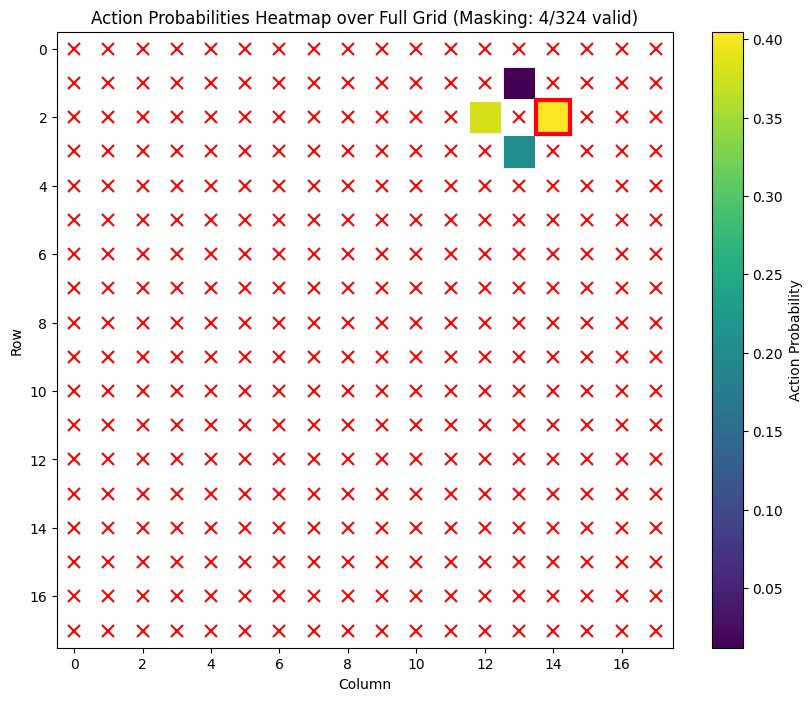

Episode 1 | Total Reward: 22.62 | Steps: 49


In [6]:
# Load trained agent
loaded_agent = RecurrentPPOAgent.load_complete(
    'models/RecurrentPPO_LSTM_18x18_action_masked.pkl',  # Custom LSTM agent we just trained
    env_constructor=lambda: VoltageDistributionEnv(),
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space)
)

# Run visualization with action masking enabled
main(loaded_agent, episodes=1, render_delay=0.2, use_action_masking=True)